# Introduction to SQL and Advanced Functions

**1.  Explain the fundamental differences between DDL, DML, and DQL
commands in SQL. Provide one example for each type of command?**

  -  The fundamental difference lies in their purpose: DDL (Data Definition Language) defines and modifies the structure or schema of the database; DML (Data Manipulation Language) alters and manages the actual data records stored within those structures; and DQL (Data Query Language) is exclusively used to retrieve or view data without altering it.


 1. DDL Example (CREATE) :

     This command designs the structural layout of a new table called employees. It dictates what type of data can live inside it but does not add any rows.


     Primary Focus : Database structure and blueprint.


     Database Impact : Structural changes (adds/deletes tables or columns).


     Transaction Control : Auto-committed: Changes are permanent and cannot be rolled back.


     Core Commands : CREATE, ALTER, DROP, TRUNCATE.

In [ ]:
%load_ext sql
%sql sqlite://


In [ ]:
%%sql
CREATE TABLE employees (
    employee_id INT PRIMARY KEY,
    first_name VARCHAR(50),
    salary DECIMAL(10, 2)
);


 * sqlite://
Done.


[]

2. DML Example (INSERT) :

     Once the structure exists, this command populates it by injecting a concrete data record into the rows of the employees table.

     Primary Focus : Table rows and data records.

     Database Impact : Content changes (inserts/edits/removes rows).

     Transaction Control : Rollback supported: Changes can be undone before committing.

     Core Commands : INSERT, UPDATE, DELETE.

In [ ]:
%%sql
INSERT INTO employees (employee_id, first_name, salary)
VALUES (101, 'Alice', 75000.00);


 * sqlite://
1 rows affected.


[]

3. DQL Example (SELECT) :

     This command pulls the data from the database to present it to the user. The underlying data in the table remains completely untouched.

     Primary Focus : Data retrieval and reporting

     Database Impact : No changes; read-only operations.

     Transaction Control : N/A (Does not modify data).

     Core Commands : SELECT

In [ ]:
import prettytable
if 'DEFAULT' not in prettytable.__dict__:
    prettytable.__dict__['DEFAULT'] = prettytable.DEFAULT

%config SqlMagic.style = 'DEFAULT'
%config SqlMagic.autopandas = False

/tmp/ipykernel_1225/3368820320.py:3: DeprecationWarning: the 'DEFAULT' constant is deprecated, use the 'TableStyle' enum instead
  prettytable.__dict__['DEFAULT'] = prettytable.DEFAULT


In [ ]:
%%sql
SELECT first_name, salary
FROM employees
WHERE salary > 50000.00;

 * sqlite://
Done.


first_name,salary
Alice,75000


**2.   What is the purpose of SQL constraints? Name and describe three common types of constraints, providing a simple scenario where each would be useful?**

  -  The purpose of SQL constraints is to enforce rules on the data columns of a table to ensure data accuracy, reliability, and integrity. By restricting the types of data that can be inserted, updated, or deleted, constraints serve as a validation engine that prevents accidental data corruption or invalid entries. If a database operation violates a constraint, the database system rejects the transaction entirely.

  Here are three common types of SQL constraints, their descriptions, and simple scenarios where they are highly useful:


  1. PRIMARY KEY :

     • Description: A combination of NOT NULL and UNIQUE. It uniquely identifies each record/row in a database table. A table can have only one primary key, and it cannot contain any duplicate or NULL (empty) values.

     • Useful Scenario: E-commerce Customer Accounts. If you are designing a Users table, you can apply a PRIMARY KEY to a UserID column. This guarantees that every customer has an entirely distinct identifier, making it impossible for two different users to accidentally share the same account or confuse their order histories.


  2. NOT NULL :

     • Description: This constraint prevents a column from accepting or storing NULL values. It forces the column to always contain data, meaning a user cannot leave that specific field blank when creating or updating a record.

     • Useful Scenario: User Authentication Sign-ups. In a Users table, you would apply the NOT NULL constraint to the PasswordHash and Email columns. This ensures that no one can mistakenly register an account without providing an email address or creating a password, avoiding broken account states.


  3. FOREIGN KEY :

     • Description: A foreign key is a column (or group of columns) in one table that links to the primary key of another table. It establishes and enforces referential integrity, ensuring that relationships between tables remain consistent and preventing actions that would destroy those links.

     • Useful Scenario: Online Shopping Orders. In an e-commerce database, you might have an Orders table and a Customers table. By placing a FOREIGN KEY on the CustomerID column inside the Orders table (linking back to the Customers table), the database prevents anyone from placing an order for a customer ID that doesn't actually exist.

**3.   Explain the difference between LIMIT and OFFSET clauses in SQL. How
would you use them together to retrieve the third page of results, assuming each page has 10 records?**

  -  in SQL, LIMIT specifies how many records to retrieve, while OFFSET specifies how many records to skip.

  1. Difference between LIMIT and OFFSET

     LIMIT :

     Restricts the number of rows returned.

     LIMIT 10 returns at most 10 records.

     OFFSET :

     Skips a specified number of rows before returning results.

     OFFSET 20 skips the first 20 records.

  2. How to retrieve the third page of results

     Suppose each page contains 10 records.

     Page 1: Records 1–10

     Page 2: Records 11–20

     Page 3: Records 21–30

     To retrieve the third page, we skip the first 20 records and return the next 10.

**4.  What is a Common Table Expression (CTE) in SQL, and what are its main
benefits? Provide a simple SQL example demonstrating its usage?**

  -  A Common Table Expression (CTE) is a temporary, named result set in SQL that you can reference within a single SELECT, INSERT, UPDATE, or DELETE statement. Defined using the WITH clause, a CTE acts like a virtual table that exists only for the duration of that specific query execution


     Main Benefits of CTEs :

     • Improved Readability: Instead of nesting complex subqueries inside each other (which can quickly become unreadable), a CTE lets you write from top to bottom, breaking logic into clean, modular blocks.

     • Code Reusability: You can reference the same CTE multiple times within the main query. A traditional subquery must be rewritten every time you want to reuse its logic.

     • Support for Recursion: "Recursive CTEs" can reference themselves. This makes them essential for traversing hierarchical or tree-structured data like organizational charts or bill-of-materials.

     • Easier Maintenance: Because the data-gathering logic is isolated at the beginning of your query, debugging and making changes is much simpler.


     Simple SQL Example :

     Suppose you have a table named Employees and you want to find all employees who earn more than the average company salary.

     Using a CTE, you can first calculate the average salary, then instantly filter your employees against it:
     





In [ ]:
import sqlite3
import pandas as pd

# 1. Connect to an in-memory SQLite database
conn = sqlite3.connect(':memory:')

# 2. Create the Employees table
conn.execute('''
CREATE TABLE Employees (
    EmployeeID INT,
    FirstName TEXT,
    LastName TEXT,
    Salary INT
);
''')

# 3. Insert mock data
mock_data = [
    (1, 'Alice', 'Smith', 90000),
    (2, 'Bob', 'Jones', 55000),
    (3, 'Charlie', 'Brown', 110000),
    (4, 'Diana', 'Prince', 45000),
    (5, 'Evan', 'Wright', 75000)
]
conn.executemany("INSERT INTO Employees VALUES (?, ?, ?, ?);", mock_data)
conn.commit()

print("Database and mock data created successfully!")


Database and mock data created successfully!


In [ ]:
# Define your SQL CTE query string
cte_query = '''
WITH AvgSalaryCTE AS (
    SELECT AVG(Salary) AS OverallAverage
    FROM Employees
)
SELECT
    EmployeeID,
    FirstName,
    LastName,
    Salary
FROM
    Employees
CROSS JOIN
    AvgSalaryCTE
WHERE
    Salary > AvgSalaryCTE.OverallAverage;
'''

# Execute the query and read it into a Pandas DataFrame
df = pd.read_sql_query(cte_query, conn)

# Display the result
df


,EmployeeID,FirstName,LastName,Salary
0,1,Alice,Smith,90000
1,3,Charlie,Brown,110000


**5.  Describe the concept of SQL Normalization and its primary goals. Briefly
explain the first three normal forms (1NF, 2NF, 3NF)?**

  -  SQL Normalization is a systematic database design technique used to organize tables in a relational database to minimize data redundancy and protect data integrity. Developed by Edgar F. Codd, it involves breaking a large, complex table down into smaller, well-structured tables and defining relationships between them.


     Primary Goals of Normalization :

     The main objectives of normalizing a database schema include:

     • Eliminating Data Redundancy: Preventing the same piece of information from being needlessly duplicated across multiple rows or tables.

     • Preventing Data Anomalies: Eliminating structural design flaws that cause data inconsistencies:

	  • Insertion Anomaly: Being unable to insert certain data because it requires other, unrelated data to be present.

	  • Update Anomaly: Having to update multiple rows just to change a single piece of information, raising the risk of inconsistent data.

	  • Deletion Anomaly: Unintentionally losing critical information when a specific row is deleted.

     • Ensuring Logical Dependencies: Making sure data is stored logically so that non-key attributes truly belong to the primary key they are mapped to.


  1. First Normal Form (1NF) :

     To achieve 1NF, a table must store only atomic (indivisible) values.

     • The Rule: A single column cannot contain multiple items or comma-separated lists (e.g., storing Java, Python, C++ in a single Skills cell is a violation).

     • Solution: Split multi-valued data into separate rows or entirely separate rows/tables so that every intersection of a row and column contains exactly one value.


  2. Second Normal Form (2NF) :

     To reach 2NF, the table must be in 1NF and have no partial dependencies.

     • The Rule: This rule primarily impacts tables that use a composite primary key (a primary key made up of two or more columns). Every non-key column must depend on the entire composite key, not just a portion of it. For example, in a table with a composite key of OrderID + ProductID, a column like CustomerPhone depends only on OrderID, creating a partial dependency.

     • Solution: Move the partially dependent columns out into a separate table (e.g., an Orders table and an OrderDetails table).


  3. Third Normal Form (3NF) :

     To achieve 3NF, the table must be in 2NF and have no transitive dependencies.

     • The Rule: Non-key columns must depend only on the primary key, and not on other non-key columns. For example, in an Employees table where EmployeeID is the primary key, if you have columns for DepartmentID and DepartmentName, DepartmentName actually depends on DepartmentID (a non-key) rather than directly on EmployeeID.

     • Solution: Move the transitively dependent attributes into their own standalone lookup table (e.g., a dedicated Departments table) linked via a foreign key.

**6.  Create a database named ECommerceDB and perform the following
tasks:**

  1. Create the following tables with appropriate data types and constraints

     ● Categories

     ○ CategoryID (INT, PRIMARY KEY)

     ○ CategoryName (VARCHAR(50), NOT NULL, UNIQUE)


     ● Products

     ○ ProductID (INT, PRIMARY KEY)

     ○ ProductName (VARCHAR(100), NOT NULL, UNIQUE)

     ○ CategoryID (INT, FOREIGN KEY → Categories)

     ○ Price (DECIMAL(10,2), NOT NULL)

     ○ StockQuantity (INT)


     ● Customers

     ○ CustomerID (INT, PRIMARY KEY)

     ○ CustomerName (VARCHAR(100), NOT NULL)

     ○ Email (VARCHAR(100), UNIQUE)

     ○ JoinDate (DATE)


     ● Orders

     ○ OrderID (INT, PRIMARY KEY)

     ○ CustomerID (INT, FOREIGN KEY → Customers)

     ○ OrderDate (DATE, NOT NULL)

     ○ TotalAmount (DECIMAL(10,2))

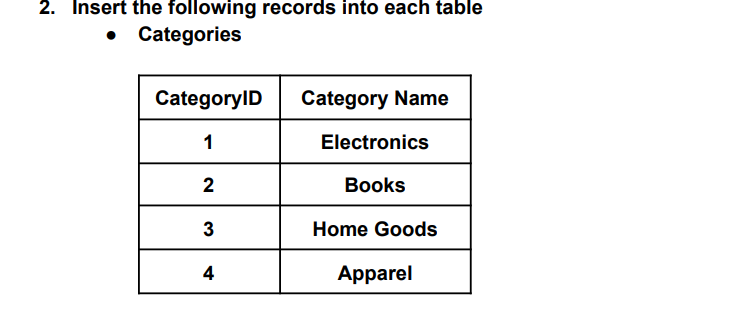

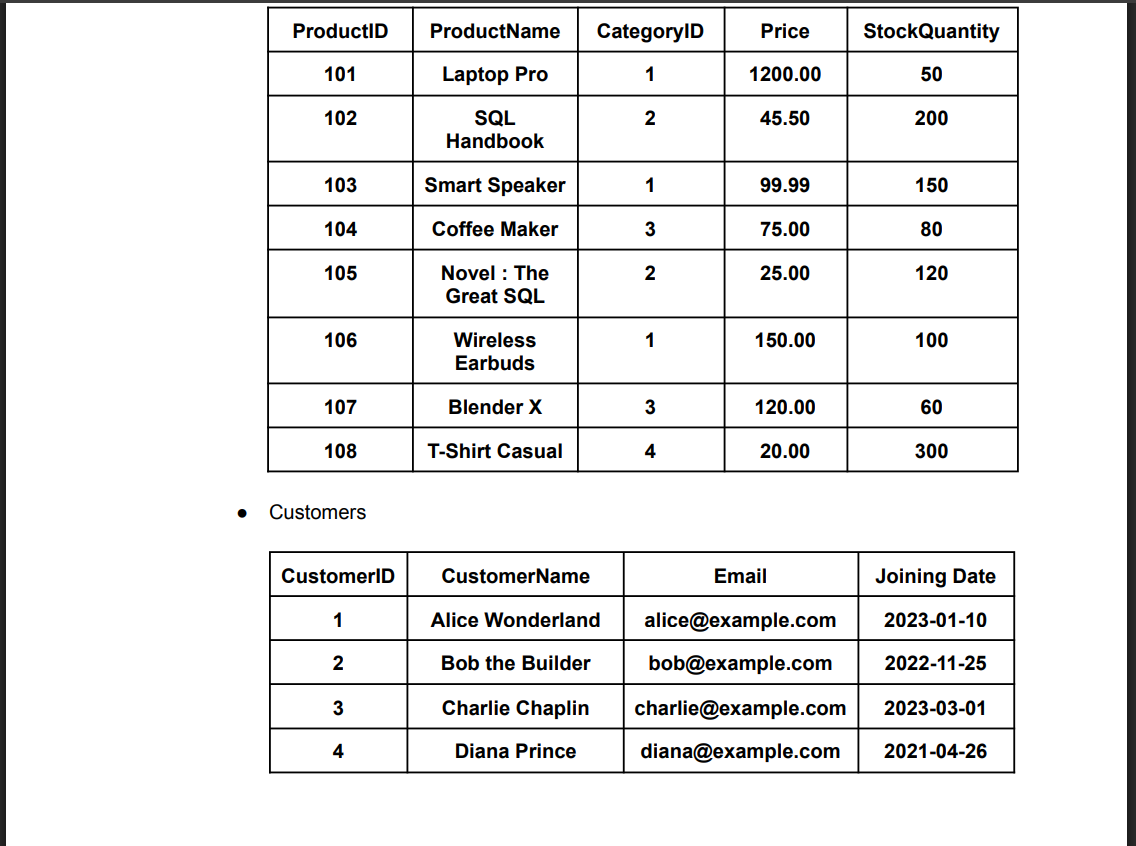

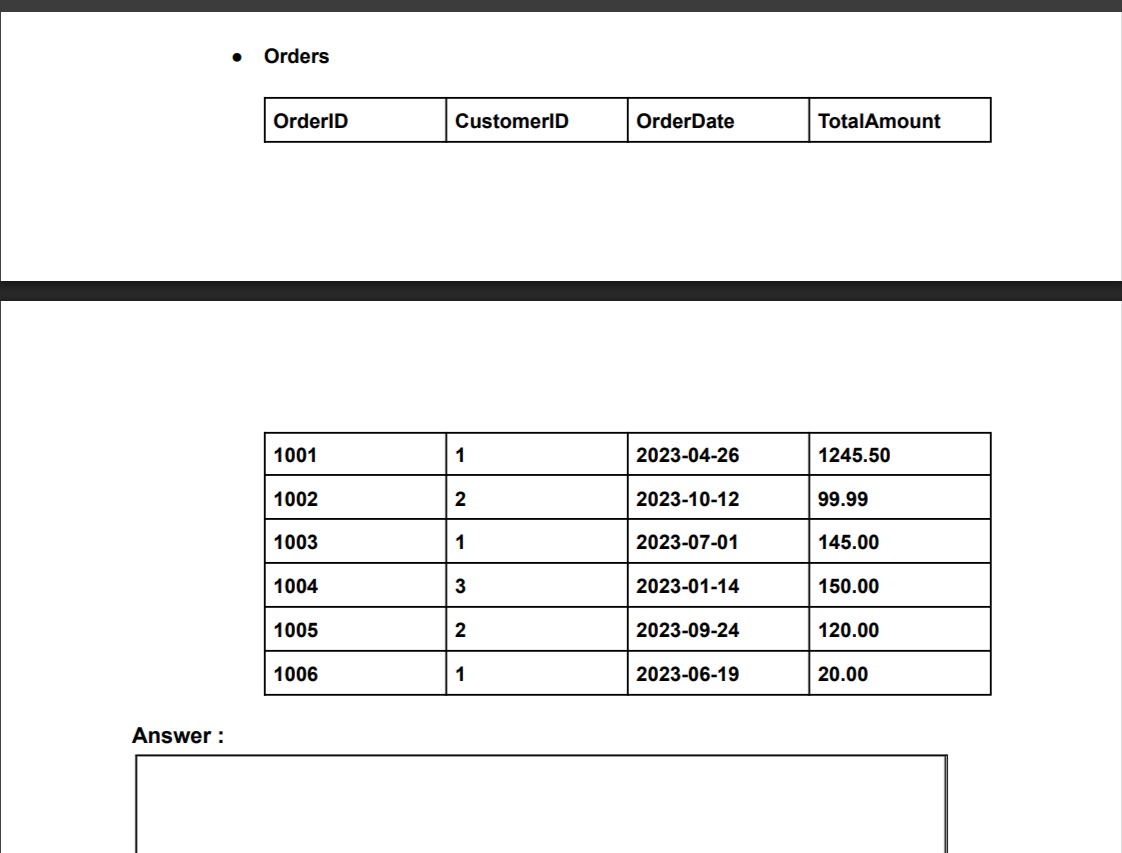

In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("ECommerceDB.db")   # creates the database file
conn.execute("PRAGMA foreign_keys = ON")   # SQLite needs this to enforce foreign keys
cur = conn.cursor()
print("Connected to ECommerceDB.db")

Connected to ECommerceDB.db


In [3]:
cur.executescript("""
DROP TABLE IF EXISTS Orders;
DROP TABLE IF EXISTS Products;
DROP TABLE IF EXISTS Customers;
DROP TABLE IF EXISTS Categories;

CREATE TABLE Categories (
    CategoryID   INT PRIMARY KEY,
    CategoryName VARCHAR(50) NOT NULL UNIQUE
);

CREATE TABLE Products (
    ProductID     INT PRIMARY KEY,
    ProductName   VARCHAR(100) NOT NULL UNIQUE,
    CategoryID    INT,
    Price         DECIMAL(10,2) NOT NULL,
    StockQuantity INT,
    FOREIGN KEY (CategoryID) REFERENCES Categories(CategoryID)
);

CREATE TABLE Customers (
    CustomerID   INT PRIMARY KEY,
    CustomerName VARCHAR(100) NOT NULL,
    Email        VARCHAR(100) UNIQUE,
    JoinDate     DATE
);

CREATE TABLE Orders (
    OrderID     INT PRIMARY KEY,
    CustomerID  INT,
    OrderDate   DATE NOT NULL,
    TotalAmount DECIMAL(10,2),
    FOREIGN KEY (CustomerID) REFERENCES Customers(CustomerID)
);
""")
conn.commit()
print("Tables created")

Tables created


In [4]:
cur.executescript("""
INSERT INTO Categories (CategoryID, CategoryName) VALUES
    (1, 'Electronics'),
    (2, 'Books'),
    (3, 'Home Goods'),
    (4, 'Apparel');

INSERT INTO Products (ProductID, ProductName, CategoryID, Price, StockQuantity) VALUES
    (101, 'Laptop Pro', 1, 1200.00, 50),
    (102, 'SQL Handbook', 2, 45.50, 200),
    (103, 'Smart Speaker', 1, 99.99, 150),
    (104, 'Coffee Maker', 3, 75.00, 80),
    (105, 'Novel : The Great SQL', 2, 25.00, 120),
    (106, 'Wireless Earbuds', 1, 150.00, 100),
    (107, 'Blender X', 3, 120.00, 60),
    (108, 'T-Shirt Casual', 4, 20.00, 300);

INSERT INTO Customers (CustomerID, CustomerName, Email, JoinDate) VALUES
    (1, 'Alice Wonderland', 'alice@example.com', '2023-01-10'),
    (2, 'Bob the Builder', 'bob@example.com', '2022-11-25'),
    (3, 'Charlie Chaplin', 'charlie@example.com', '2023-03-01'),
    (4, 'Diana Prince', 'diana@example.com', '2021-04-26');

INSERT INTO Orders (OrderID, CustomerID, OrderDate, TotalAmount) VALUES
    (1001, 1, '2023-04-26', 1245.50),
    (1002, 2, '2023-10-12', 99.99),
    (1003, 1, '2023-07-01', 145.00),
    (1004, 3, '2023-01-14', 150.00),
    (1005, 2, '2023-09-24', 120.00),
    (1006, 1, '2023-06-19', 20.00);
""")
conn.commit()
print("Records inserted")

Records inserted


In [5]:
for table in ["Categories", "Products", "Customers", "Orders"]:
    print(f"--- {table} ---")
    display(pd.read_sql_query(f"SELECT * FROM {table}", conn))

--- Categories ---


,CategoryID,CategoryName
0,1,Electronics
1,2,Books
2,3,Home Goods
3,4,Apparel


--- Products ---


,ProductID,ProductName,CategoryID,Price,StockQuantity
0,101,Laptop Pro,1,1200.00,50
1,102,SQL Handbook,2,45.50,200
2,103,Smart Speaker,1,99.99,150
3,104,Coffee Maker,3,75.00,80
4,105,Novel : The Great SQL,2,25.00,120
5,106,Wireless Earbuds,1,150.00,100
6,107,Blender X,3,120.00,60
7,108,T-Shirt Casual,4,20.00,300


--- Customers ---


,CustomerID,CustomerName,Email,JoinDate
0,1,Alice Wonderland,alice@example.com,2023-01-10
1,2,Bob the Builder,bob@example.com,2022-11-25
2,3,Charlie Chaplin,charlie@example.com,2023-03-01
3,4,Diana Prince,diana@example.com,2021-04-26


--- Orders ---


,OrderID,CustomerID,OrderDate,TotalAmount
0,1001,1,2023-04-26,1245.50
1,1002,2,2023-10-12,99.99
2,1003,1,2023-07-01,145.00
3,1004,3,2023-01-14,150.00
4,1005,2,2023-09-24,120.00
5,1006,1,2023-06-19,20.00


In [6]:
query = """
SELECT * FROM Orders;
"""
pd.read_sql_query(query, conn)

,OrderID,CustomerID,OrderDate,TotalAmount
0,1001,1,2023-04-26,1245.50
1,1002,2,2023-10-12,99.99
2,1003,1,2023-07-01,145.00
3,1004,3,2023-01-14,150.00
4,1005,2,2023-09-24,120.00
5,1006,1,2023-06-19,20.00


**7.  Generate a report showing CustomerName, Email, and the
TotalNumberofOrders for each customer. Include customers who have not placed
any orders, in which case their TotalNumberofOrders should be 0. Order the results by Customer Name?**

In [7]:
query = """
SELECT c.CustomerName,
       c.Email,
       COUNT(o.OrderID) AS TotalNumberofOrders
FROM Customers c
LEFT JOIN Orders o ON c.CustomerID = o.CustomerID
GROUP BY c.CustomerID, c.CustomerName, c.Email
ORDER BY c.CustomerName;
"""
pd.read_sql_query(query, conn)

,CustomerName,Email,TotalNumberofOrders
0,Alice Wonderland,alice@example.com,3
1,Bob the Builder,bob@example.com,2
2,Charlie Chaplin,charlie@example.com,1
3,Diana Prince,diana@example.com,0


**8.   Retrieve Product Information with Category: Write a SQL query to
display the ProductName, Price, StockQuantity, and CategoryName for all
products. Order the results by CategoryName and then ProductName alphabetically?**

In [9]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("ECommerceDB.db")
conn.execute("PRAGMA foreign_keys = ON")

conn.executescript("""
DROP TABLE IF EXISTS Orders;
DROP TABLE IF EXISTS Products;
DROP TABLE IF EXISTS Customers;
DROP TABLE IF EXISTS Categories;

CREATE TABLE Categories (
    CategoryID   INT PRIMARY KEY,
    CategoryName VARCHAR(50) NOT NULL UNIQUE
);
CREATE TABLE Products (
    ProductID     INT PRIMARY KEY,
    ProductName   VARCHAR(100) NOT NULL UNIQUE,
    CategoryID    INT,
    Price         DECIMAL(10,2) NOT NULL,
    StockQuantity INT,
    FOREIGN KEY (CategoryID) REFERENCES Categories(CategoryID)
);
CREATE TABLE Customers (
    CustomerID   INT PRIMARY KEY,
    CustomerName VARCHAR(100) NOT NULL,
    Email        VARCHAR(100) UNIQUE,
    JoinDate     DATE
);
CREATE TABLE Orders (
    OrderID     INT PRIMARY KEY,
    CustomerID  INT,
    OrderDate   DATE NOT NULL,
    TotalAmount DECIMAL(10,2),
    FOREIGN KEY (CustomerID) REFERENCES Customers(CustomerID)
);

INSERT INTO Categories VALUES (1,'Electronics'),(2,'Books'),(3,'Home Goods'),(4,'Apparel');

INSERT INTO Products VALUES
    (101,'Laptop Pro',1,1200.00,50),
    (102,'SQL Handbook',2,45.50,200),
    (103,'Smart Speaker',1,99.99,150),
    (104,'Coffee Maker',3,75.00,80),
    (105,'Novel : The Great SQL',2,25.00,120),
    (106,'Wireless Earbuds',1,150.00,100),
    (107,'Blender X',3,120.00,60),
    (108,'T-Shirt Casual',4,20.00,300);

INSERT INTO Customers VALUES
    (1,'Alice Wonderland','alice@example.com','2023-01-10'),
    (2,'Bob the Builder','bob@example.com','2022-11-25'),
    (3,'Charlie Chaplin','charlie@example.com','2023-03-01'),
    (4,'Diana Prince','diana@example.com','2021-04-26');

INSERT INTO Orders VALUES
    (1001,1,'2023-04-26',1245.50),
    (1002,2,'2023-10-12',99.99),
    (1003,1,'2023-07-01',145.00),
    (1004,3,'2023-01-14',150.00),
    (1005,2,'2023-09-24',120.00),
    (1006,1,'2023-06-19',20.00);
""")
conn.commit()

# Report 1: customers and their total number of orders
q1 = """
SELECT c.CustomerName, c.Email, COUNT(o.OrderID) AS TotalNumberofOrders
FROM Customers c
LEFT JOIN Orders o ON c.CustomerID = o.CustomerID
GROUP BY c.CustomerID, c.CustomerName, c.Email
ORDER BY c.CustomerName;
"""
print("Customers and total orders")
print(pd.read_sql_query(q1, conn).to_string(index=False))

# Report 2: products with category
q2 = """
SELECT p.ProductName, p.Price, p.StockQuantity, c.CategoryName
FROM Products p
INNER JOIN Categories c ON p.CategoryID = c.CategoryID
ORDER BY c.CategoryName, p.ProductName;
"""
print("\nProducts with category")
print(pd.read_sql_query(q2, conn).to_string(index=False))

Customers and total orders
    CustomerName               Email  TotalNumberofOrders
Alice Wonderland   alice@example.com                    3
 Bob the Builder     bob@example.com                    2
 Charlie Chaplin charlie@example.com                    1
    Diana Prince   diana@example.com                    0

Products with category
          ProductName   Price  StockQuantity CategoryName
       T-Shirt Casual   20.00            300      Apparel
Novel : The Great SQL   25.00            120        Books
         SQL Handbook   45.50            200        Books
           Laptop Pro 1200.00             50  Electronics
        Smart Speaker   99.99            150  Electronics
     Wireless Earbuds  150.00            100  Electronics
            Blender X  120.00             60   Home Goods
         Coffee Maker   75.00             80   Home Goods


**9.  Write a SQL query that uses a Common Table Expression (CTE) and a
Window Function (specifically ROW_NUMBER() or RANK()) to display the
CategoryName, ProductName, and Price for the top 2 most expensive products in
each CategoryName?**

In [10]:
q3 = """
WITH RankedProducts AS (
    SELECT c.CategoryName,
           p.ProductName,
           p.Price,
           ROW_NUMBER() OVER (
               PARTITION BY c.CategoryName
               ORDER BY p.Price DESC, p.ProductName
           ) AS PriceRank
    FROM Products p
    INNER JOIN Categories c ON p.CategoryID = c.CategoryID
)
SELECT CategoryName, ProductName, Price
FROM RankedProducts
WHERE PriceRank <= 2
ORDER BY CategoryName, Price DESC;
"""
pd.read_sql_query(q3, conn)

,CategoryName,ProductName,Price
0,Apparel,T-Shirt Casual,20.0
1,Books,SQL Handbook,45.5
2,Books,Novel : The Great SQL,25.0
3,Electronics,Laptop Pro,1200.0
4,Electronics,Wireless Earbuds,150.0
5,Home Goods,Blender X,120.0
6,Home Goods,Coffee Maker,75.0


10.  You are hired as a data analyst by Sakila Video Rentals, a global movie
rental company. The management team is looking to improve decision-making by
analyzing existing customer, rental, and inventory data.

     Using the Sakila database, answer the following business questions to support key strategic initiatives.

     Tasks & Questions:

      1. Identify the top 5 customers based on the total amount they’ve spent. Include customer name, email, and total amount spent.

      2. Which 3 movie categories have the highest rental counts? Display the category name and number of times movies from that category were rented.

      3. Calculate how many films are available at each store and how many of those have never been rented.

      4. Show the total revenue per month for the year 2023 to analyze business seasonality.

      5. Identify customers who have rented more than 10 times in the last 6 months.

In [11]:
# --- Setup: download Sakila (SQLite version) and connect ---
!git clone -q https://github.com/bradleygrant/sakila-sqlite3.git
import sqlite3
import pandas as pd

conn = sqlite3.connect("sakila-sqlite3/sakila_master.db")

def run(title, query):
    print(f"\n=== {title} ===")
    display(pd.read_sql_query(query, conn))

# 1. Top 5 customers by total amount spent
run("Q1: Top 5 customers by total spend", """
SELECT c.first_name || ' ' || c.last_name AS CustomerName,
       c.email AS Email,
       SUM(p.amount) AS TotalAmountSpent
FROM customer c
JOIN payment p ON c.customer_id = p.customer_id
GROUP BY c.customer_id, c.first_name, c.last_name, c.email
ORDER BY TotalAmountSpent DESC
LIMIT 5;
""")

# 2. Top 3 categories by rental count
run("Q2: Top 3 categories by rentals", """
SELECT cat.name AS CategoryName,
       COUNT(r.rental_id) AS RentalCount
FROM rental r
JOIN inventory i      ON r.inventory_id = i.inventory_id
JOIN film_category fc ON i.film_id = fc.film_id
JOIN category cat     ON fc.category_id = cat.category_id
GROUP BY cat.category_id, cat.name
ORDER BY RentalCount DESC
LIMIT 3;
""")

# 3. Films per store and films never rented
run("Q3: Films per store and never-rented films", """
SELECT store_id AS StoreID,
       COUNT(*) AS TotalFilms,
       SUM(CASE WHEN times_rented = 0 THEN 1 ELSE 0 END) AS NeverRentedFilms
FROM (
    SELECT i.store_id, i.film_id, COUNT(r.rental_id) AS times_rented
    FROM inventory i
    LEFT JOIN rental r ON i.inventory_id = r.inventory_id
    GROUP BY i.store_id, i.film_id
)
GROUP BY store_id
ORDER BY store_id;
""")

# 4. Monthly revenue for a year (change the year below)
YEAR = "2023"   # Sakila only has 2005-2006 data, so 2023 is empty; try "2005"
run(f"Q4: Monthly revenue for {YEAR}", f"""
SELECT strftime('%Y-%m', payment_date) AS Month,
       SUM(amount) AS TotalRevenue
FROM payment
WHERE strftime('%Y', payment_date) = '{YEAR}'
GROUP BY strftime('%Y-%m', payment_date)
ORDER BY Month;
""")

# 5. Customers with more than 10 rentals in the last 6 months
#    ("last 6 months" is measured back from the latest rental date in the data)
run("Q5: Customers with more than 10 rentals in the last 6 months", """
SELECT c.first_name || ' ' || c.last_name AS CustomerName,
       c.email AS Email,
       COUNT(r.rental_id) AS RentalCount
FROM customer c
JOIN rental r ON c.customer_id = r.customer_id
WHERE r.rental_date >= date((SELECT MAX(rental_date) FROM rental), '-6 months')
GROUP BY c.customer_id, c.first_name, c.last_name, c.email
HAVING COUNT(r.rental_id) > 10
ORDER BY RentalCount DESC;
""")


=== Q1: Top 5 customers by total spend ===


,CustomerName,Email,TotalAmountSpent
0,KARL SEAL,KARL.SEAL@sakilacustomer.org,221.55
1,ELEANOR HUNT,ELEANOR.HUNT@sakilacustomer.org,216.54
2,CLARA SHAW,CLARA.SHAW@sakilacustomer.org,195.58
3,RHONDA KENNEDY,RHONDA.KENNEDY@sakilacustomer.org,194.61
4,MARION SNYDER,MARION.SNYDER@sakilacustomer.org,194.61



=== Q2: Top 3 categories by rentals ===


,CategoryName,RentalCount
0,Sports,1179
1,Animation,1166
2,Action,1112



=== Q3: Films per store and never-rented films ===


,StoreID,TotalFilms,NeverRentedFilms
0,1,759,0
1,2,762,0



=== Q4: Monthly revenue for 2023 ===


,Month,TotalRevenue



=== Q5: Customers with more than 10 rentals in the last 6 months ===


,CustomerName,Email,RentalCount
0,HELEN HARRIS,HELEN.HARRIS@sakilacustomer.org,16
1,ELEANOR HUNT,ELEANOR.HUNT@sakilacustomer.org,16
2,MICHELLE CLARK,MICHELLE.CLARK@sakilacustomer.org,15
3,ANGELA HERNANDEZ,ANGELA.HERNANDEZ@sakilacustomer.org,14
4,SHERRY MARSHALL,SHERRY.MARSHALL@sakilacustomer.org,14
...,...,...,...
80,DUANE TUBBS,DUANE.TUBBS@sakilacustomer.org,11
81,FRANKLIN TROUTMAN,FRANKLIN.TROUTMAN@sakilacustomer.org,11
82,ROLAND SOUTH,ROLAND.SOUTH@sakilacustomer.org,11
83,ERIK GUILLEN,ERIK.GUILLEN@sakilacustomer.org,11
